**Loading libraries**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import pandas as pd

**Define the map from set to integer and integer to set**

In [ ]:
n_strains = 2
n_classes = 2**n_strains

def int2set(index, n_strains):
    history_set = set()
    for i in range(n_strains):
        if index & (1 << i):
            history_set.add(i+1)
    return history_set

def set2int(strain_set):
    index = 0
    for strain in strain_set:
        index |= (1 << (strain - 1))
    return index

def history_classes(n_strains):
    n_classes = 2**n_strains

    for i in range(n_classes):
        set_rep = int2set(i, n_strains)
        print(f"Index {i:2d}: {set_rep}")

history_classes(n_strains)

Index  0: set()
Index  1: {1}
Index  2: {2}
Index  3: {1, 2}


**Define cross-immunity matrix**

In [ ]:
cross_escape = 0.8

def sigma_matrix(n_strains, cross_escape=0.8):
    n_classes = 2**n_strains
    sigma = np.zeros((n_classes, n_strains))
    for J in range(n_classes):
        H = int2set(J, n_strains)
        for i in range(1, n_strains+1):
            if i in H:
                sigma[J, i-1] = 0.0
            elif any(o in H for o in range(1, n_strains+1) if o != i):
                sigma[J, i-1] = cross_escape
            else:
                sigma[J, i-1] = 1.0
    return sigma

sigma = sigma_matrix(n_strains, cross_escape=cross_escape)

print(sigma_matrix(n_strains))

[[1.  1. ]
 [0.  0.8]
 [0.8 0. ]
 [0.  0. ]]


**Constructing system in matrix framework**

In [ ]:
def construct_sys(n_strains, beta_vec, gamma_vec, mu, N, sigma):
    n_classes = 2**n_strains
    eligible = [[(((J >> i) & 1) == 0) for J in range(n_classes)] for i in range(n_strains)]

    def rhs(t, y):
        dy = np.zeros_like(y)
        S = y[:n_classes]
        I = y[n_classes:].reshape(n_strains, n_classes)

        I_tot = I.sum(axis=1)
        Lambda = beta_vec * (I_tot / N)

        #---S compartment---
        for J in range(n_classes):
            H = int2set(J, n_strains)
            births = mu * N if J == 0 else 0.0
            inf_out = 0.0
            for i in range(n_strains):
                if eligible[i][J]:
                    inf_out += sigma[J, i] * Lambda[i] * S[J]
            rec_in = 0.0
            for i in range(n_strains):
                if (i+1) in H:
                    K = set(H); K.remove(i+1)
                    rec_in += gamma_vec[i] * I[i, set2int(K)]
            dy[J] = births + rec_in - inf_out - mu*S[J]

        #---I compartment---
        for i in range(n_strains):
            for J in range(n_classes):
                idx = n_classes + i*n_classes + J
                if eligible[i][J]:
                    infection = sigma[J, i] * Lambda[i] * S[J]
                    removal   = (mu + gamma_vec[i]) * I[i, J]
                    dy[idx] = infection - removal
                else:
                    dy[idx] = -mu * I[i, J]
        return dy

    return rhs

def tilde_sys(y, eps_seed, n_strains):
    n_classes = 2**n_strains
    S = y[:n_classes].copy()
    I = y[n_classes:].reshape(n_strains, n_classes).copy()
    for J in range(n_classes):
        if ((J >> 1) & 1) == 0:
            seed = eps_seed * S[J]
            S[J] -= seed
            I[1, J] += seed
    return np.concatenate([S, I.ravel()])

**Setting parameter values to the system**

In [ ]:
beta1=0.32
beta2=0.50
gamma=1/7
mu=1/(70*365)
N=10000
cross_escape=0.8
t_star=60.0
T=160.0
eps0=1.0
eps_seed=2e-3

beta_vec = np.array([beta1, beta2], dtype=float)
gamma_vec = np.array([gamma, gamma], dtype=float)
sys = construct_sys(n_strains, beta_vec, gamma_vec, mu, N, sigma)

S0 = np.zeros(n_classes); S0[0] = N - eps0
I0 = np.zeros((n_strains, n_classes)); I0[0, 0] = eps0
y0 = np.concatenate([S0, I0.ravel()])

sol1 = solve_ivp(sys, (0.0, t_star), y0, method="RK45", rtol=1e-7, atol=1e-9, max_step=0.5)
y_minus = sol1.y[:, -1]
y_plus = tilde_sys(y_minus, eps_seed, n_strains)
sol2 = solve_ivp(sys, (t_star, T), y_plus, method="RK45", rtol=1e-7, atol=1e-9, max_step=0.5)

t = np.concatenate([sol1.t, sol2.t])
Y = np.hstack([sol1.y, sol2.y])

I = Y[n_classes:, :].reshape(n_strains, n_classes, len(t))
I1_total = I[0].sum(axis=0)
I2_total = I[1].sum(axis=0)
I2_invade = np.where(t>=t_star, I2_total/N, np.nan)

**Plotting the two-strain replacement**

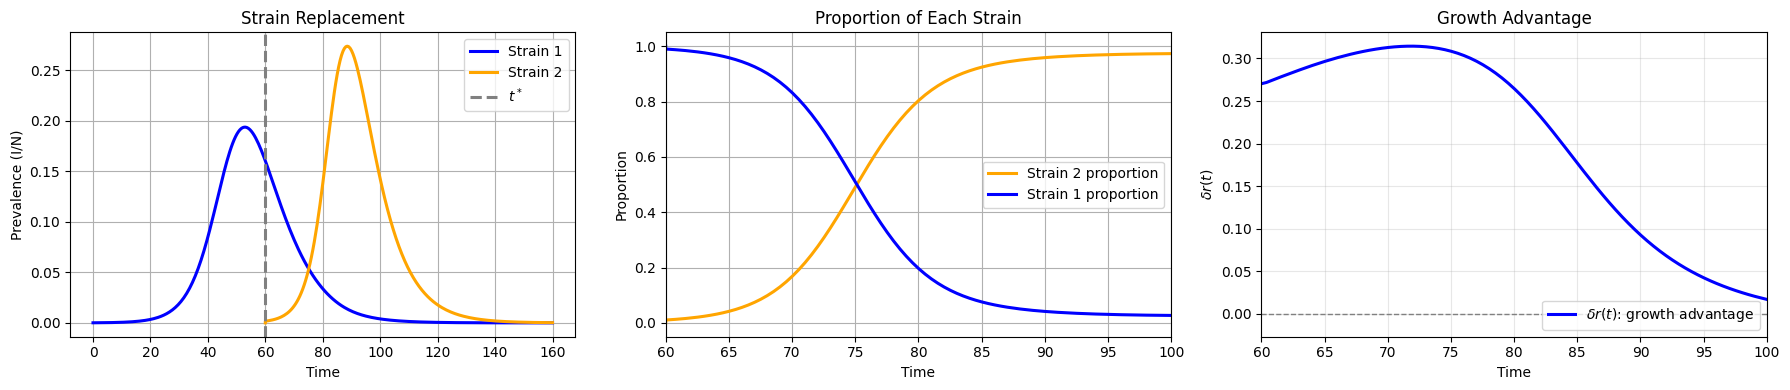

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

#---Dynamics---
axes[0].plot(t, I1_total/N, label="Strain 1", linewidth=2.2, color="blue")
axes[0].plot(t, I2_invade, label="Strain 2", linewidth=2.2, color="orange")
axes[0].axvline(t_star, linestyle="--", color="grey", linewidth=2.2, label="$t^*$")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Prevalence (I/N)")
axes[0].set_title("Strain Replacement")
axes[0].legend()
axes[0].grid()

#---Proportion---
Z1 = I1_total/N
Z2 = I2_invade
axes[1].plot(t, Z2/(Z1+Z2), label="Strain 2 proportion", linewidth=2.2, color="orange")
axes[1].plot(t, Z1/(Z1+Z2), label="Strain 1 proportion", linewidth=2.2, color="blue")
axes[1].set_xlim([60, 100])
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Proportion")
axes[1].set_title("Proportion of Each Strain")
axes[1].legend()
axes[1].grid()

#---Growth Advantage---
axes[2].plot(t[1:], np.diff(np.log(Z2/Z1))/np.diff(t), color="blue", lw=2.2, label=r"$\delta r(t)$: growth advantage")
axes[2].axhline(0, linestyle="--", color="grey", lw=1)
axes[2].set_title("Growth Advantage")
axes[2].set_xlabel("Time")
axes[2].set_ylabel(r"$\delta r(t)$")
axes[2].grid(True, alpha=0.3)
axes[2].legend(loc="lower right")
axes[2].set_xlim(60, 100)

plt.tight_layout()
plt.show()